In [1]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(23)

# Generate first class sample data
mu_vec1 = np.array([0, 0, 0])
cov_mat1 = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)

df = pd.DataFrame(class1_sample, columns=['feature1', 'feature2', 'feature3'])
df['target'] = 1

# Generate second class sample data
mu_vec2 = np.array([1, 1, 1])
cov_mat2 = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)

df1 = pd.DataFrame(class2_sample, columns=['feature1', 'feature2', 'feature3'])
df1['target'] = 0

# Combine and shuffle the dataset
df = pd.concat([df, df1], ignore_index=True)
df = df.sample(40)

In [2]:
df.head()

,feature1,feature2,feature3,target
2,-0.367548,-1.137460,-1.322148,1
34,0.177061,-0.598109,1.226512,0
14,0.420623,0.411620,-0.071324,1
11,1.968435,-0.547788,-0.679418,1
12,-2.506230,0.146960,0.606195,1


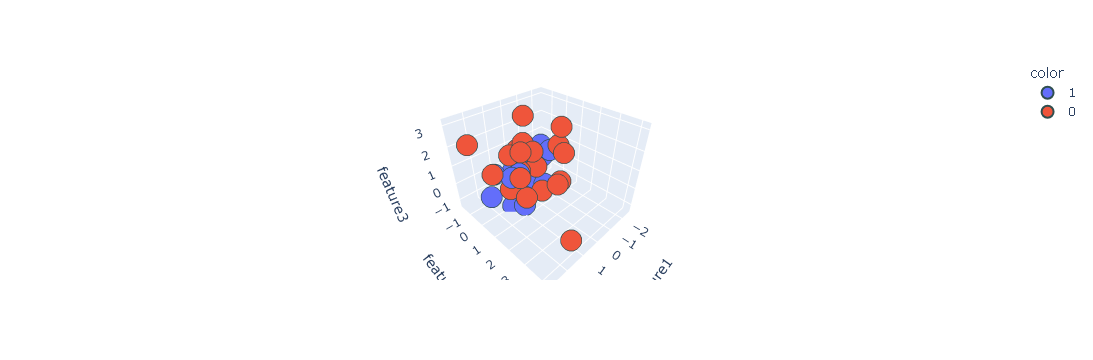

In [4]:
import plotly.express as px

#y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x='feature1', y='feature2', z='feature3',
                    color=df['target'].astype('str'))

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()

In [5]:
# Step 1 - Apply standard scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:, 0:3] = scaler.fit_transform(df.iloc[:, 0:3])

In [6]:
# Calculate Covariance Matrix
covariance_matrix = np.cov([df.iloc[:, 0], df.iloc[:, 1], df.iloc[:, 2]])
print('Covariance Matrix: \n', covariance_matrix)

Covariance Matrix: 
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [7]:
# Eigen values and Eigen vectors
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

In [9]:
eigen_vectors

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442],
       [-0.52848211,  0.72025103,  0.44938304]])

In [10]:
eigen_values

array([1.3536065 , 0.94557084, 0.77774573])

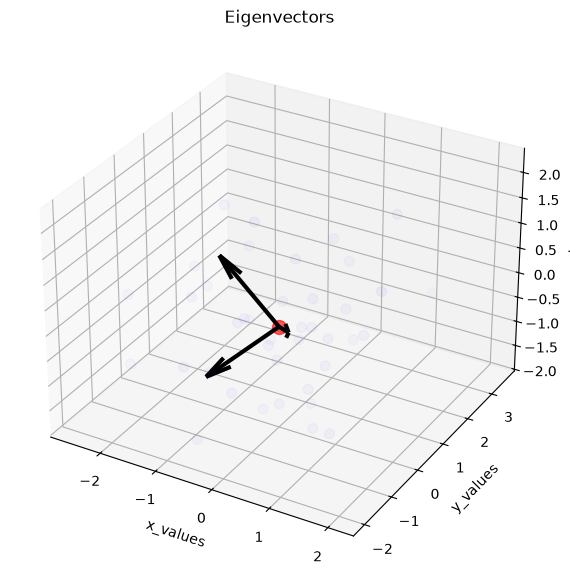

In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot data points and mean
ax.scatter(df['feature1'], df['feature2'], df['feature3'], c='blue', alpha=0.2, s=50)
mean_coords = [df['feature1'].mean(), df['feature2'].mean(), df['feature3'].mean()]
ax.scatter(*mean_coords, color='red', s=100, alpha=0.8, label='Mean')

# Plot eigenvectors using quiver
for v in eigen_vectors.T:
    ax.quiver(
        mean_coords[0], mean_coords[1], mean_coords[2],  # Starting point (mean)
        v[0], v[1], v[2],                               # Direction vector
        length=1.5,                                     # Scale length if needed
        color='black', lw=3
    )

ax.set_xlabel('x_values')
ax.set_ylabel('y_values')
ax.set_zlabel('z_values')
plt.title('Eigenvectors')
plt.show()

In [13]:
pc = eigen_vectors[:, 0:2]
pc

array([[-0.53875915, -0.69363291],
       [-0.65608325, -0.01057596],
       [-0.52848211,  0.72025103]])

In [15]:
# Remove the .T because pc is already shaped (3, 2)
transformed_df = np.dot(df.iloc[:, 0:3], pc)

new_df = pd.DataFrame(transformed_df, columns=['PC1', 'PC2'])
new_df['target'] = df['target'].values
new_df.head()

,PC1,PC2,target
0,2.302877,-0.757593,1
1,0.524464,0.520221,0
2,0.380275,-0.459443,1
3,0.534262,-1.773773,1
4,1.610434,1.747819,1


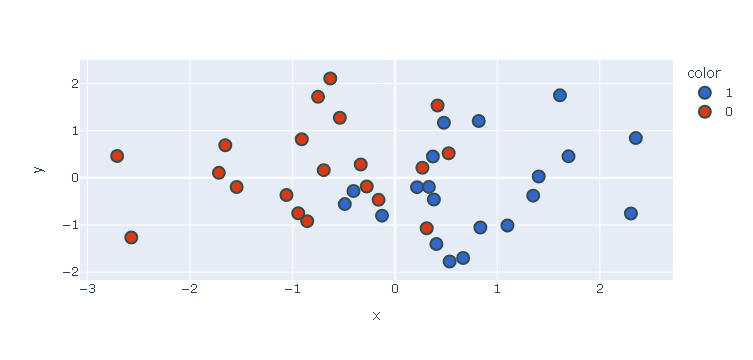

In [16]:
new_df['target'] = new_df['target'].astype('str')
fig = px.scatter(x=new_df['PC1'],
                 y=new_df['PC2'],
                 color=new_df['target'],
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()